# 04 · Comparar las cuatro versiones y transferir el estilo

Ya tenemos A (VLM sin entrenar) y B (VLM con LoRA). Añadimos dos comparaciones honestas:

- **C · Línea base pequeña.** Una red de visión clásica y diminuta (**MobileNetV3-small**, 2,5 M parámetros, preentrenada en ImageNet) **congelada**, que convierte la foto en un vector de 576 números, y encima una **regresión lineal** (Ridge) que predice los cinco ajustes. Si C hace lo mismo que B, ¿para qué queremos un LLM?
- **D · Método clásico de Reinhard (2001).** No predice ajustes: pasa la foto a espacio de color **Lab** (L = luminosidad, a = verde-rojo, b = azul-amarillo) y hace que el contenido tenga la **misma media y desviación** de cada canal que la referencia. Sin entrenamiento y sin JSON.

El notebook tiene dos etapas (parámetro `ETAPA`), para poder repartirlo en dos *jobs* de CI:

- `c_d`: solo calcula C y D y guarda `resultados/pred_C.jsonl`, `metricas_C.json` y `metricas_D.json`.
- `completo` (por defecto): lee lo de A, B, C y D, hace la tabla (`resultados/tabla_comparativa.csv` y `.json`), el panel (`resultados/panel_transferencia.png`) y registra en MLflow A, C, D y la comparativa (B ya lo registró el 03). Si falta C, lo calcula.

In [1]:
import os
N_EJEMPLOS = int(os.environ.get("ESTILO_N_EJEMPLOS", "60"))
EPOCAS = int(os.environ.get("ESTILO_EPOCAS", "2"))
RESOLUCION = int(os.environ.get("ESTILO_RESOLUCION", "224"))
MODELO = os.environ.get("ESTILO_MODELO", "HuggingFaceTB/SmolVLM-256M-Instruct")
CARPETA_TRABAJO = os.environ.get("ESTILO_TRABAJO", "_trabajo")
ETAPA = os.environ.get("ESTILO_ETAPA", "completo")  # «c_d» o «completo»
N_PANEL = 4  # parejas que se dibujan en el panel

In [2]:
import csv, json
import numpy as np
import matplotlib.pyplot as plt
import comun_estilo as ce

assert ETAPA in ("c_d", "completo"), ETAPA
plt.rcParams["figure.dpi"] = 55
trabajo = ce.carpeta_trabajo(CARPETA_TRABAJO)
resultados = trabajo / "resultados"; resultados.mkdir(exist_ok=True)
hilos = ce.limitar_hilos()
import torch, torchvision, sklearn
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| scikit-learn", sklearn.__version__, "| hilos:", hilos, "| ETAPA:", ETAPA)
train, test = ce.leer_parejas(trabajo, "train"), ce.leer_parejas(trabajo, "test")

def leer_pred(v):
    filas = (resultados / f"pred_{v}.jsonl").read_text(encoding="utf-8").splitlines()
    return {d["id"]: d for d in map(json.loads, filter(None, filas))}

def guardar_pred(v, d):
    (resultados / f"pred_{v}.jsonl").write_text("\n".join(json.dumps(dict(x, id=k)) for k, x in d.items()), encoding="utf-8")

pred = {}
print(len(train), "de entrenamiento,", len(test), "de test")

torch 2.15.0+cpu | torchvision 0.29.2+cpu | scikit-learn 1.9.1 | hilos: 12 | ETAPA: completo
210 de entrenamiento, 60 de test


## 1. Versión C: MobileNetV3-small congelada + regresión

Es «aprendizaje por transferencia» de la S3 en su versión más simple: no se entrena la red, solo la regresión de encima (segundos). Como referencias aún más tontas añadimos «neutro» (contestar siempre «no se tocó nada») y «media» (contestar siempre la media de train).

Añadimos también **C_color**: la misma regresión, pero en vez de los 576 números de MobileNet le damos **27 estadísticas de color** calculadas a mano: en Lab, la media, la desviación y los percentiles 5, 50 y 95 de cada canal (15 números); en RGB, la media, la desviación y los percentiles 1 y 99 (12). Sin red neuronal. Sirve para responder a la pregunta incómoda: ¿hace falta un modelo grande para esto?

In [3]:
from sklearn.linear_model import RidgeCV
Y = np.array([[f["ajustes"][k] for k in ce.NOMBRES] for f in train])

if ETAPA == "c_d" or not (resultados / "pred_C.jsonl").exists():
    from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

    pesos = MobileNet_V3_Small_Weights.IMAGENET1K_V1
    red = mobilenet_v3_small(weights=pesos).eval()
    transformar = pesos.transforms()

    def rasgos(filas):
        with torch.no_grad():
            x = torch.stack([transformar(ce.abrir(trabajo, f["editada"])) for f in filas])
            return red.avgpool(red.features(x)).flatten(1).numpy()  # 576 números por foto

    with ce.Cronometro() as c_train:
        regresion = RidgeCV(alphas=np.logspace(-2, 3, 12)).fit(rasgos(train), Y)
    with ce.Cronometro() as c_inf:
        salida = regresion.predict(rasgos(test))
    guardar_pred("C", {f["id"]: {"pred": ce.recortar_a_rango(dict(zip(ce.NOMBRES, fila)))} for f, fila in zip(test, salida)})
    metC = ce.error_por_ajuste([ce.recortar_a_rango(dict(zip(ce.NOMBRES, fila))) for fila in salida], [f["ajustes"] for f in test])
    metC.update(s_entrenamiento=c_train.s, s_inferencia_por_foto=c_inf.s / len(test), alfa=float(regresion.alpha_),
                mb_modelo=round((sum(p.numel() for p in red.parameters()) + regresion.coef_.size) * 4 / 2**20, 2))
    (resultados / "metricas_C.json").write_text(json.dumps(metC, indent=1), encoding="utf-8")
    print(f"C: entrenamiento (rasgos + regresión) {c_train.s:.1f} s; inferencia {metC['s_inferencia_por_foto'] * 1000:.0f} ms por foto; "
          f"alfa elegido {regresion.alpha_:.3g}; tamaño ≈ {metC['mb_modelo']} MB en float32")
else:
    print("C ya calculado en la etapa c_d: se lee de resultados/")
pred["C"] = leer_pred("C")

# C_color: 27 estadísticas de color + la misma regresión (segundos, sin red neuronal)
with ce.Cronometro() as c_color:
    reg_color = RidgeCV(alphas=np.logspace(-3, 3, 13)).fit(np.array([ce.estadisticas_color(ce.abrir(trabajo, f["editada"])) for f in train]), Y)
    salida_color = reg_color.predict(np.array([ce.estadisticas_color(ce.abrir(trabajo, f["editada"])) for f in test]))
pred["C_color"] = {f["id"]: {"pred": ce.recortar_a_rango(dict(zip(ce.NOMBRES, fila)))} for f, fila in zip(test, salida_color)}
print(f"C_color: entrenamiento + inferencia {c_color.s:.1f} s en total ({salida_color.shape[0]} fotos de test, {reg_color.coef_.shape[1]} estadísticas)")

media = {k: float(np.mean([f["ajustes"][k] for f in train])) for k in ce.NOMBRES}
pred["media"] = {f["id"]: {"pred": media} for f in test}
pred["neutro"] = {f["id"]: {"pred": dict(ce.NEUTRO)} for f in test}

C: entrenamiento (rasgos + regresión) 1.1 s; inferencia 5 ms por foto; alfa elegido 123; tamaño ≈ 9.71 MB en float32


C_color: entrenamiento + inferencia 2.6 s en total (60 fotos de test, 27 estadísticas)


## 2. Transferir el estilo de verdad: cómo se mide

Para cada foto editada de test (la **referencia**) cogemos otra foto original de test (el **contenido**). Como sabemos qué ajustes tenía la referencia, sabemos también cómo **debería** quedar el contenido: el **objetivo**.

- **ΔE medio respecto al objetivo** (CIEDE2000, en Lab): diferencia de color píxel a píxel con el resultado ideal. Hacia 1 apenas se nota; por encima de 10 se ve claramente distinto. **Más bajo es mejor.**
- **Distancia de histogramas con la referencia** (Bhattacharyya media de L, a y b; 0 = misma distribución de colores). Mide si el resultado «tiene los colores» de la referencia, aunque las fotos sean distintas. Ojo: un método que copia la distribución de la referencia (como D) gana aquí aunque se aleje del objetivo.
- **SSIM con el contenido** (0 a 1, en grises): cuánto se conserva la estructura de la foto. Cambiar el color también lo baja un poco; por eso damos también el SSIM del propio objetivo como techo razonable.

In [4]:
def transferir(version, ref, cont):
    """Foto de referencia -> (modelo) -> JSON -> aplicar el JSON a la foto de contenido."""
    img_ref, img_cont = ce.abrir(trabajo, ref["editada"]), ce.abrir(trabajo, cont["original"])
    if version == "D":
        return ce.reinhard(img_ref, img_cont)
    if version == "objetivo":
        return ce.aplicar_ajustes(img_cont, ref["ajustes"])
    if version == "sin cambio":
        return img_cont
    return ce.aplicar_ajustes(img_cont, pred[version][ref["id"]]["pred"])

def medir(version):
    m = {"delta_e_objetivo": [], "dist_hist_referencia": [], "ssim_contenido": [], "ms_aplicar": []}
    for ref, cont in ce.parejas_transferencia(test):
        img_ref, img_cont = ce.abrir(trabajo, ref["editada"]), ce.abrir(trabajo, cont["original"])
        with ce.Cronometro() as c:
            salida = transferir(version, ref, cont)
        m["ms_aplicar"].append(c.s * 1000)
        m["delta_e_objetivo"].append(ce.delta_e(salida, transferir("objetivo", ref, cont)))
        m["dist_hist_referencia"].append(ce.distancia_histogramas(salida, img_ref))
        m["ssim_contenido"].append(ce.ssim_contenido(salida, img_cont))
    return {k: float(np.mean(x)) for k, x in m.items()}

if ETAPA == "c_d":
    metC = json.loads((resultados / "metricas_C.json").read_text(encoding="utf-8")); metC.update(medir("C"))
    metD = medir("D"); metD.update(s_entrenamiento=0.0, s_inferencia_por_foto=metD["ms_aplicar"] / 1000, mb_modelo=0.0)
    for v, m in (("C", metC), ("D", metD)):
        (resultados / f"metricas_{v}.json").write_text(json.dumps(m, indent=1), encoding="utf-8")
        print(v, {k: round(x, 3) for k, x in m.items() if not k.startswith("mae")})
    print("Etapa c_d terminada: métricas de C y D guardadas en resultados/")

## 3. Tabla comparativa (etapa `completo`)

Primero, **¿quién lee mejor los ajustes?** (MAE normalizado por ajuste; 0 = perfecto). **Un modelo que no mejora a «media» no ha aprendido nada de la foto.** Después, la tabla completa con las métricas de imagen, los tiempos y los tamaños.

In [5]:
if ETAPA == "completo":
    pred["A"], pred["B"] = leer_pred("A"), leer_pred("B")
    met = {v: json.loads((resultados / f"metricas_{v}.json").read_text(encoding="utf-8")) for v in "ABC"}
    reales = [f["ajustes"] for f in test]
    errores = {v: ce.error_por_ajuste([pred[v][f["id"]]["pred"] for f in test], reales) for v in ("neutro", "media", "A", "B", "C", "C_color")}
    print(f"{'versión':8s}" + "".join(f"{k:>12s}" for k in ce.NOMBRES) + f"{'MEDIA':>9s}")
    for v, e in errores.items():
        print(f"{v:8s}" + "".join(f"{e['maen_'+k]:12.3f}" for k in ce.NOMBRES) + f"{e['mae_normalizado_medio']:9.3f}")

    filas = []
    for v in ["sin cambio", "objetivo", "media", "A", "B", "C", "C_color", "D"]:
        fila = {"version": v, **medir(v)}
        if v in errores:
            fila["mae_normalizado_medio"] = errores[v]["mae_normalizado_medio"]
        if v in ("A", "B"):
            fila.update(formato_correcto=met[v]["formato_correcto"], s_inferencia_por_foto=met[v]["segundos_por_foto"], mb_modelo=met["B"]["base_mb"])
        if v == "A":
            fila["s_entrenamiento"] = 0.0
        if v == "B":
            fila.update(s_entrenamiento=met["B"]["segundos_entrenamiento"] + met["B"]["segundos_preparacion"], mb_adaptador=met["B"]["adaptador_mb"])
        if v == "C":
            fila.update({k: met["C"][k] for k in ("s_entrenamiento", "s_inferencia_por_foto", "mb_modelo")})
        if v == "C_color":
            fila.update(s_entrenamiento=c_color.s, mb_modelo=round(reg_color.coef_.size * 4 / 2**20, 4))
        if v == "D":
            fila.update(s_entrenamiento=0.0, s_inferencia_por_foto=fila["ms_aplicar"] / 1000, mb_modelo=0.0)
        filas.append(fila)

    columnas = ["version", "mae_normalizado_medio", "formato_correcto", "delta_e_objetivo", "dist_hist_referencia", "ssim_contenido",
                "s_inferencia_por_foto", "s_entrenamiento", "mb_modelo", "mb_adaptador"]
    with open(resultados / "tabla_comparativa.csv", "w", newline="", encoding="utf-8") as fh:
        w = csv.writer(fh); w.writerow(columnas)
        for f in filas:
            w.writerow([f["version"]] + [("" if c not in f else f"{f[c]:.3f}") for c in columnas[1:]])
    (resultados / "tabla_comparativa.json").write_text(json.dumps(filas, indent=1, ensure_ascii=False), encoding="utf-8")
    print()
    print((resultados / "tabla_comparativa.csv").read_text(encoding="utf-8").replace(",", " | "))
    print("(C_color: el tiempo de entrenamiento incluye también la inferencia de test)")
else:
    print("ETAPA = c_d: la tabla se hace en la etapa «completo»")

versión   exposicion temperatura       tinte   contraste  saturacion    MEDIA
neutro         0.262       0.250       0.249       0.242       0.290    0.259
media          0.262       0.251       0.253       0.240       0.292    0.259
A              0.488       0.492       0.432       0.372       0.380    0.433
B              0.299       0.342       0.285       0.317       0.308    0.310
C              0.245       0.208       0.242       0.222       0.228    0.229
C_color        0.119       0.158       0.147       0.126       0.208    0.151



version | mae_normalizado_medio | formato_correcto | delta_e_objetivo | dist_hist_referencia | ssim_contenido | s_inferencia_por_foto | s_entrenamiento | mb_modelo | mb_adaptador
sin cambio |  |  | 14.413 | 0.534 | 1.000 |  |  |  | 
objetivo |  |  | 0.000 | 0.391 | 0.820 |  |  |  | 
media | 0.259 |  | 14.715 | 0.535 | 0.988 |  |  |  | 
A | 0.433 | 0.550 | 22.206 | 0.594 | 0.815 | 5.050 | 0.000 | 493.900 | 
B | 0.310 | 1.000 | 15.986 | 0.552 | 0.937 | 4.910 | 1123.348 | 493.900 | 7.060
C | 0.229 |  | 13.212 | 0.508 | 0.948 | 0.005 | 1.137 | 9.710 | 
C_color | 0.151 |  | 7.500 | 0.414 | 0.860 |  | 2.624 | 0.001 | 
D |  |  | 14.367 | 0.241 | 0.779 | 0.015 | 0.000 | 0.000 | 

(C_color: el tiempo de entrenamiento incluye también la inferencia de test)


## 4. Panel visual

Cada fila es una pareja: la **referencia** (de donde copiamos el estilo), el **contenido** (la foto a la que se lo aplicamos), el **objetivo** (cómo debería quedar) y las cuatro versiones. Debajo de cada salida, su ΔE con el objetivo (más bajo = mejor).

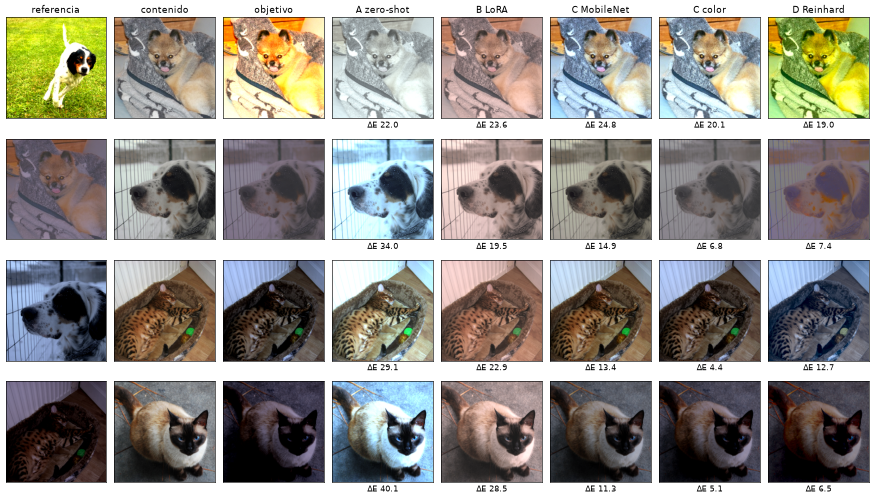

In [6]:
if ETAPA == "completo":
    cols = ["referencia", "contenido", "objetivo", "A", "B", "C", "C_color", "D"]
    titulos = {"A": "A zero-shot", "B": "B LoRA", "C": "C MobileNet", "C_color": "C color", "D": "D Reinhard"}
    parejas = ce.parejas_transferencia(test)[:N_PANEL]
    fig, ejes = plt.subplots(len(parejas), len(cols), figsize=(16, 2.3 * len(parejas)), squeeze=False)
    for fila, (ref, cont) in enumerate(parejas):
        objetivo = transferir("objetivo", ref, cont)
        for col, v in enumerate(cols):
            img = ce.abrir(trabajo, ref["editada"]) if v == "referencia" else ce.abrir(trabajo, cont["original"]) if v == "contenido" else transferir(v, ref, cont)
            eje = ejes[fila, col]; eje.imshow(img); eje.set_xticks([]); eje.set_yticks([])
            if fila == 0:
                eje.set_title(titulos.get(v, v), fontsize=12)
            if v in titulos:
                eje.set_xlabel(f"ΔE {ce.delta_e(img, objetivo):.1f}", fontsize=11)
    plt.tight_layout()
    for destino in (resultados / "panel_transferencia.png", "figuras/04_panel_transferencia.png"):
        ce.guardar_figura(destino)
    plt.show()

## 5. La aplicación final y el registro en MLflow

Foto de referencia → modelo B → JSON → aplicar a otra foto. El JSON es lo interesante: es **legible**, se puede **corregir a mano** y se puede **aplicar a mil fotos** sin volver a llamar al modelo. Después registramos A, C, D y la comparativa en la misma base temporal de MLflow donde el 03 dejó B.

In [7]:
if ETAPA == "completo":
    ref, cont = ce.parejas_transferencia(test)[0]
    print("Lo que escribió B para la referencia:", pred["B"][ref["id"]]["respuesta"])
    print("Ajustes reales de la referencia:     ", ce.a_json(ref["ajustes"]))
    print("Lo que predice C_color:              ", ce.a_json(pred["C_color"][ref["id"]]["pred"]))

    mlflow = ce.mlflow_local(trabajo)
    por_version = {f["version"]: f for f in filas}
    for v, nombre in (("A", "A_zero_shot"), ("C", "C_mobilenet_ridge"), ("C_color", "C_color_ridge"), ("D", "D_reinhard")):
        with mlflow.start_run(run_name=nombre):
            mlflow.log_params({"version": v, "n_test": len(test), "hilos": hilos, "modelo": MODELO if v == "A" else "-"})
            mlflow.log_metrics({k: x for k, x in por_version[v].items() if isinstance(x, float)})
    with mlflow.start_run(run_name="comparativa"):
        mlflow.log_artifact(str(resultados / "tabla_comparativa.csv"))
        mlflow.log_artifact(str(resultados / "panel_transferencia.png"))
    print("Runs en MLflow:", sorted(r.info.run_name for r in mlflow.search_runs(experiment_names=["pico-llm-estilo"], output_format="list")))

Lo que escribió B para la referencia: {"exposicion": 0.22, "temperatura": 0.62, "tinte": 0.62, "contraste": 0.82, "saturacion": 0.68}
Ajustes reales de la referencia:      {"exposicion": 0.45, "temperatura": 0.5, "tinte": 0.03, "contraste": 1.35, "saturacion": 1.69}
Lo que predice C_color:               {"exposicion": 0.31, "temperatura": -0.26, "tinte": -0.11, "contraste": 1.17, "saturacion": 1.27}


Runs en MLflow: ['A3_explicacion_one_shot', 'A_zero_shot', 'B3_explicacion_lora', 'B_lora', 'C_color_ridge', 'C_mobilenet_ridge', 'D_reinhard', 'comparativa']


## 6. Conclusiones (con las cifras de la ejecución de referencia: 300 fotos, 210 train / 30 val / 60 test, 3 épocas)

1. **A (zero-shot) no sirve.** Sin ayuda, el modelo describe la foto. Si le empezamos la respuesta escribe un JSON, pero **copia los extremos de los rangos del prompt** (0,7, −1, 0,2…): su error es peor que contestar «no se tocó nada».
2. **B (LoRA) aprende el formato, no la tarea.** Tras 3 épocas el 100 % de las respuestas son JSON válidos, pero los números **casi no cambian de una foto a otra**: la pérdida se estanca y el error queda **peor que «media»**. Es un ejemplo de manual de por qué una métrica de formato o una pérdida que baja no bastan: hay que compararse con una línea base tonta.
3. **C (MobileNet + regresión) apenas mejora a «media».** Una red preentrenada para reconocer *qué* hay en la foto (perro, gato) guarda poca información útil sobre *cómo* está coloreada; es nuestra explicación, no algo medido aquí.
4. **C_color (27 estadísticas de color + regresión) es la mejor con diferencia**: el menor error en los ajustes y el menor ΔE con el objetivo, en segundos y sin red neuronal.
5. **D (Reinhard)** copia la distribución de color de la referencia (gana en distancia de histogramas), pero al copiarla «entera» también arrastra los colores del contenido de la referencia (el césped verde) y **no se acerca más al objetivo que no hacer nada**.

**Lección para producción:** antes de afinar un LLM, mide una línea base barata. Aquí el LLM de visión pequeño, entrenado así, es la herramienta equivocada para leer números de color; lo que sí aporta la idea es una salida **en texto (JSON)** que se lee, se corrige y se aplica a mil fotos, y eso también lo da C_color. En el notebook 05 le damos al LLM la tarea que sí es suya: explicar ese JSON con palabras.